# EDA — Entrega T2
**Proyecto:** Predicción de demandas sísmicas (ln MIDR y Vb/W) en edificaciones de concreto armado en el Perú — E.030-2026 · PEER NGA-West2
**Curso:** Aplicaciones de IA en Estructuras (UPC)

Este notebook analiza dos fuentes:

1. `data/catalogo_arquetipos.csv`: los **40 arquetipos diseñados** (datos reales del proyecto).
2. `data/dataset_sismico_peru.csv`: la matriz de 16 000 NLTHA. **Mientras la campaña no termine**, se usa `data/dataset_sismico_peru_EJEMPLO.csv`: 14 NLTHA reales del modelo con acelerogramas **sintéticos** (`fuente = ilustrativo`). Las conclusiones sobre la respuesta sísmica que salen de esas 14 filas son ilustrativas, no estadísticas.

El notebook detecta solo qué archivo hay disponible.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 160, "display.max_columns", 40, "display.precision", 4)
sns.set_theme(style="whitegrid", context="notebook")

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, FIG = RAIZ / "data", RAIZ / "docs" / "figuras"
FIG.mkdir(parents=True, exist_ok=True)

COLORES = {"porticos": "#1f77b4", "dual": "#ff7f0e", "muros": "#2ca02c"}
ETIQ = {"porticos": "Pórticos (R0=8)", "dual": "Dual (R0=7)", "muros": "Muros (R0=6)"}
LIM_0007, LIM_00875 = 0.007, 0.00875

cat = pd.read_csv(DATA / "catalogo_arquetipos.csv")
ruta_real = DATA / "dataset_sismico_peru.csv"
if ruta_real.exists():
    df = pd.read_csv(ruta_real)
    MODO = "real"
else:
    df = pd.read_csv(DATA / "dataset_sismico_peru_EJEMPLO.csv")
    MODO = "ejemplo"
df = df[df.convergencia == 1].copy()          # fallas numéricas fuera (docs/03)
print(f"Catálogo: {cat.shape}  ·  Dataset ({MODO}): {df.shape}")
print("Fuente:", df.fuente.value_counts().to_dict())
if MODO == "ejemplo":
    print("AVISO: 14 filas ilustrativas (acelerogramas sintéticos). Usar solo para validar el flujo de EDA.")

Catálogo: (40, 41)  ·  Dataset (ejemplo): (14, 57)
Fuente: {'ilustrativo': 14}
AVISO: 14 filas ilustrativas (acelerogramas sintéticos). Usar solo para validar el flujo de EDA.


## 1. Estadísticas descriptivas del catálogo de arquetipos

In [2]:
num_cat = ["n_pisos", "H_m", "area_planta_m2", "fc_kgcm2", "densidad_muros_pct", "W_kN",
           "T1_E030_s", "T1_s", "Vs30_ms", "S", "TP_s", "C_T1", "Sa_R1_g", "V_W",
           "deriva_diseno", "pct_V_muros"]
desc = cat[num_cat].describe().T
desc["mediana"] = cat[num_cat].median()
desc["IQR"] = cat[num_cat].quantile(0.75) - cat[num_cat].quantile(0.25)
desc[["count", "mean", "std", "min", "25%", "mediana", "75%", "max", "IQR"]]

,count,mean,std,min,25%,mediana,75%,max,IQR
n_pisos,40.0,8.6000,3.4848,3.0000,6.0000,8.0000,11.0000,15.0000,5.0000
H_m,40.0,26.6400,10.8742,8.3700,18.3300,26.3100,35.3250,48.9000,16.9950
area_planta_m2,40.0,508.6450,217.0805,224.7000,332.2500,487.2500,611.8000,1200.5000,279.5500
fc_kgcm2,40.0,280.0000,59.3123,210.0000,210.0000,280.0000,350.0000,350.0000,140.0000
densidad_muros_pct,40.0,0.8123,0.9184,0.0000,0.0000,0.4150,1.3925,2.8800,1.3925
W_kN,40.0,37426.9000,21802.7471,8008.0000,21497.5000,31372.5000,50729.7500,109606.0000,29232.2500
T1_E030_s,40.0,0.5109,0.1640,0.2240,0.3997,0.5140,0.6262,0.8150,0.2265
T1_s,40.0,0.6625,0.2937,0.1680,0.4765,0.6350,0.7983,1.3010,0.3218
Vs30_ms,40.0,562.4500,131.3396,362.0000,459.5000,546.0000,669.7500,799.0000,210.2500
S,40.0,1.0251,0.0327,1.0000,1.0000,1.0040,1.0450,1.0940,0.0450


In [3]:
def iqr(x):
    return x.quantile(0.75) - x.quantile(0.25)

resumen_sist = cat.groupby("sistema").agg(
    N=("id_arquetipo", "size"),
    pisos_med=("n_pisos", "median"),
    T1_med=("T1_s", "median"), T1_IQR=("T1_s", iqr),
    rho_w_med=("densidad_muros_pct", "median"),
    V_muros_min=("pct_V_muros", "min"), V_muros_max=("pct_V_muros", "max"),
    VW_med=("V_W", "median"), deriva_max=("deriva_diseno", "max"))
resumen_sist

,N,pisos_med,T1_med,T1_IQR,rho_w_med,V_muros_min,V_muros_max,VW_med,deriva_max
sistema,,,,,,,,,
dual,14,10.5,0.8105,0.410,0.415,31.0,61.0,0.1062,0.0070
muros,13,10.0,0.6690,0.415,1.990,86.2,98.0,0.1811,0.0070
porticos,13,6.0,0.5190,0.198,0.000,0.0,0.0,0.1331,0.0068


In [4]:
print("Balance f'c:\n", pd.crosstab(cat.sistema, cat.fc_kgcm2, margins=True))
print("\nCategoría de uso:\n", pd.crosstab(cat.sistema, cat.categoria, margins=True))
print("\nSuelo E.030-2026:\n", pd.crosstab(cat.sistema, cat.suelo, margins=True))
print("\nControles: deriva ≤ 0.007:", (cat.deriva_diseno <= LIM_0007).all(),
      "· Ts < 0.65·TP:", (cat.Ts_ref_s < cat.Ts_lim_s).all(),
      "· sistema = sistema_por_V:", (cat.sistema == cat.sistema_por_V).all(),
      "· A2 en pórticos:", int(((cat.sistema == 'porticos') & (cat.categoria == 'A2')).sum()))

Balance f'c:
 fc_kgcm2  210  280  350  All
sistema                     
dual        5    4    5   14
muros       4    4    5   13
porticos    5    4    4   13
All        14   12   14   40

Categoría de uso:
 categoria  A2   B   C  All
sistema                   
dual        2   4   8   14
muros       3   3   7   13
porticos    0   4   9   13
All         5  11  24   40

Suelo E.030-2026:
 suelo     S1  S2  All
sistema              
dual       7   7   14
muros      6   7   13
porticos   7   6   13
All       20  20   40

Controles: deriva ≤ 0.007: True · Ts < 0.65·TP: True · sistema = sistema_por_V: True · A2 en pórticos: 0


### 1.1 Periodo modal vs. periodo aproximado E.030 y reparto de cortante

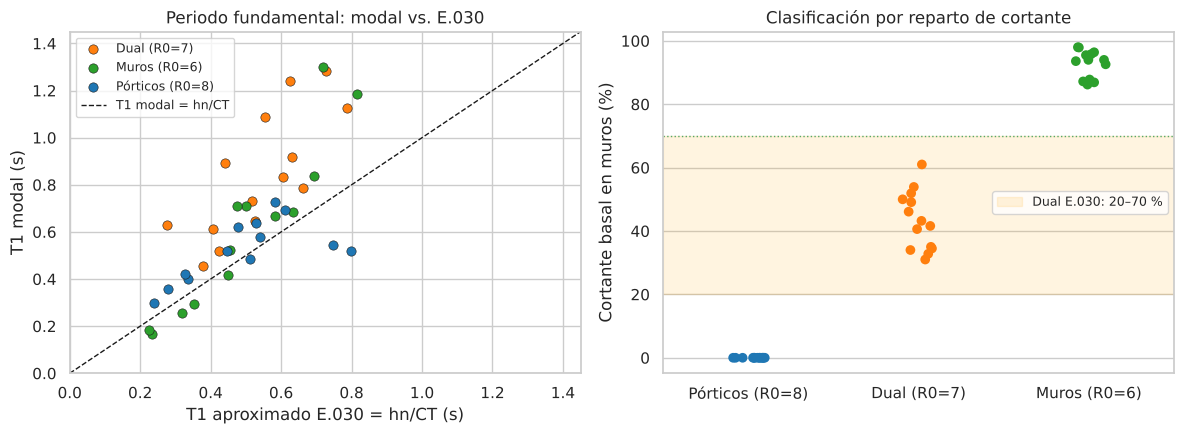

Cociente T1 modal / T1 E.030:
            min  median   max
sistema                     
dual      1.19    1.44  2.27
muros     0.72    1.15  1.81
porticos  0.65    1.19  1.30


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for s, g in cat.groupby("sistema"):
    ax[0].scatter(g.T1_E030_s, g.T1_s, c=COLORES[s], label=ETIQ[s], s=45, edgecolor="k", lw=0.4)
lim = [0, 1.45]
ax[0].plot(lim, lim, "k--", lw=1, label="T1 modal = hn/CT")
ax[0].set(xlim=lim, ylim=lim, xlabel="T1 aproximado E.030 = hn/CT (s)", ylabel="T1 modal (s)",
          title="Periodo fundamental: modal vs. E.030")
ax[0].legend(fontsize=9)
orden = ["porticos", "dual", "muros"]
sns.stripplot(data=cat, x="sistema", y="pct_V_muros", order=orden, hue="sistema",
              palette=COLORES, size=7, ax=ax[1], legend=False)
ax[1].axhspan(20, 70, color="orange", alpha=0.12, label="Dual E.030: 20–70 %")
ax[1].axhline(70, color="g", ls=":", lw=1)
ax[1].set(xlabel="", ylabel="Cortante basal en muros (%)", title="Clasificación por reparto de cortante",
          xticks=range(3), xticklabels=[ETIQ[s] for s in orden])
ax[1].legend(fontsize=9, loc="center right")
plt.tight_layout(); plt.savefig(FIG / "eda_catalogo_T1_cortante.png", dpi=150); plt.show()
ratio_T = (cat.T1_s / cat.T1_E030_s).groupby(cat.sistema).agg(["min", "median", "max"]).round(2)
print("Cociente T1 modal / T1 E.030:\n", ratio_T)

## 2. Estadísticas descriptivas del dataset NLTHA

In [6]:
FEATURES_X = ["sistema", "R0", "n_pisos", "H_m", "h_piso_m", "area_planta_m2", "T1_s", "W_kN",
              "densidad_muros_pct", "fc_kgcm2", "Z", "U", "S", "TP_s", "TL_s", "Ts_s", "C_T1",
              "Vest_W", "Sa_dis_R1_g", "PGA_g", "PGV_ms", "Sa_T1_g", "Sa_avg_g", "Arias_ms",
              "D5_95_s", "HI_m", "ASI_gs", "Mw", "Rrup_km", "Vs30_est_ms", "factor_escala"]
TARGETS = ["MIDR", "ln_MIDR", "Vb_W"]
assert len(FEATURES_X) == 31
cols = ["MIDR", "ln_MIDR", "Vb_W", "Sa_T1_g", "Sa_avg_g", "PGA_g", "PGV_ms", "Arias_ms", "D5_95_s", "factor_escala"]
d = df[cols].describe().T
d["mediana"] = df[cols].median(); d["IQR"] = df[cols].quantile(.75) - df[cols].quantile(.25)
d[["count", "mean", "std", "min", "25%", "mediana", "75%", "max", "IQR"]]

,count,mean,std,min,25%,mediana,75%,max,IQR
MIDR,14.0,0.0051,0.0047,0.0002,0.0017,0.0029,0.0091,0.0141,0.0074
ln_MIDR,14.0,-5.8387,1.2576,-8.6361,-6.3855,-5.8469,-4.7306,-4.2580,1.6549
Vb_W,14.0,0.4702,0.2769,0.1083,0.2564,0.4104,0.5558,1.0878,0.2993
Sa_T1_g,14.0,0.7381,0.4675,0.1281,0.3260,0.6548,1.0122,1.6226,0.6862
Sa_avg_g,14.0,0.6567,0.3896,0.1369,0.3107,0.6846,0.8848,1.3367,0.5741
PGA_g,14.0,0.3290,0.1938,0.0763,0.1597,0.3337,0.4542,0.6589,0.2945
PGV_ms,14.0,0.3435,0.2660,0.0661,0.1383,0.2889,0.4518,0.9506,0.3136
Arias_ms,14.0,3.7343,4.3342,0.1121,0.4941,2.1593,5.2701,14.6705,4.7760
D5_95_s,14.0,16.2571,9.1819,12.6450,12.6450,12.6450,12.6450,37.9300,0.0000
factor_escala,14.0,2.1094,1.7154,0.3941,0.8250,1.7236,2.6957,6.1440,1.8707


In [7]:
print("Casos por sistema y nivel λ:\n", pd.crosstab(df.sistema, df.nivel_escala, margins=True))
print("\nCumplimiento (fracción de casos):")
print(df.groupby("nivel_escala")[["cumple_0007", "cumple_00875"]].mean().round(2))
print("\nColapsos:", int(df.colapso.sum()), "· sf fuera de [0.2, 5]:", int((df.flag_sf_rango == 0).sum()))

Casos por sistema y nivel λ:
 nivel_escala  0.25  0.5  1.0  1.5  All
sistema                               
dual             1    1    1    1    4
muros            1    1    2    1    5
porticos         1    1    2    1    5
All              3    3    5    3   14

Cumplimiento (fracción de casos):
              cumple_0007  cumple_00875
nivel_escala                           
0.25                 1.00          1.00
0.50                 1.00          1.00
1.00                 0.60          0.60
1.50                 0.33          0.33

Colapsos: 0 · sf fuera de [0.2, 5]: 1


## 3. Distribución de los targets: MIDR y Vb/W

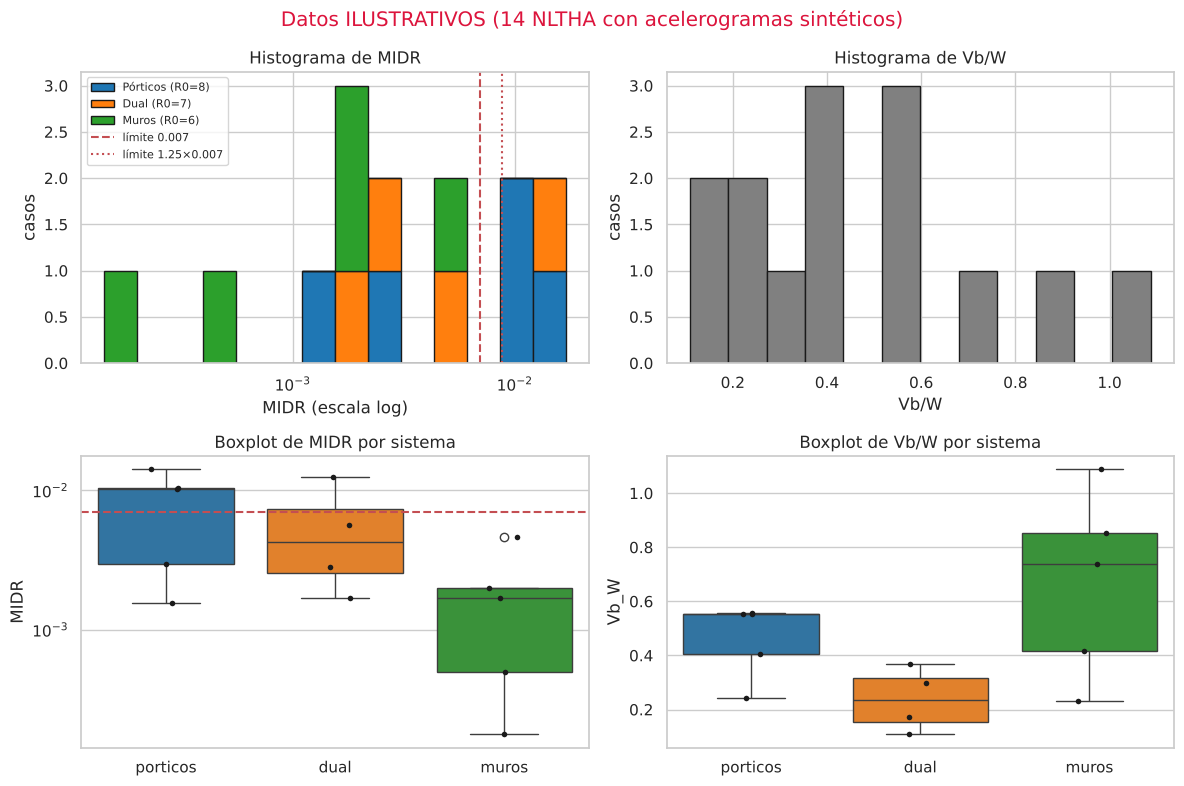

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
bins_m = np.logspace(np.log10(df.MIDR.min() * 0.8), np.log10(df.MIDR.max() * 1.2), 15)
ax[0, 0].hist([df.MIDR[df.sistema == s] for s in COLORES], bins=bins_m, stacked=True,
              color=list(COLORES.values()), label=[ETIQ[s] for s in COLORES], edgecolor="k")
ax[0, 0].set_xscale("log")
for v, ls, t in ((LIM_0007, "--", "0.007"), (LIM_00875, ":", "1.25×0.007")):
    ax[0, 0].axvline(v, color="r", ls=ls, label=f"límite {t}")
ax[0, 0].set(xlabel="MIDR (escala log)", ylabel="casos", title="Histograma de MIDR")
ax[0, 0].legend(fontsize=8)

ax[0, 1].hist(df.Vb_W, bins=12, color="gray", edgecolor="k")
ax[0, 1].set(xlabel="Vb/W", ylabel="casos", title="Histograma de Vb/W")

orden = [s for s in ["porticos", "dual", "muros"] if s in df.sistema.unique()]
sns.boxplot(data=df, x="sistema", y="MIDR", order=orden, hue="sistema", palette=COLORES,
            ax=ax[1, 0], legend=False)
sns.stripplot(data=df, x="sistema", y="MIDR", order=orden, color="k", size=4, ax=ax[1, 0])
ax[1, 0].set_yscale("log"); ax[1, 0].axhline(LIM_0007, color="r", ls="--")
ax[1, 0].set(xlabel="", title="Boxplot de MIDR por sistema")
sns.boxplot(data=df, x="sistema", y="Vb_W", order=orden, hue="sistema", palette=COLORES,
            ax=ax[1, 1], legend=False)
sns.stripplot(data=df, x="sistema", y="Vb_W", order=orden, color="k", size=4, ax=ax[1, 1])
ax[1, 1].set(xlabel="", title="Boxplot de Vb/W por sistema")
if MODO == "ejemplo":
    fig.suptitle("Datos ILUSTRATIVOS (14 NLTHA con acelerogramas sintéticos)", color="crimson")
plt.tight_layout(); plt.savefig(FIG / "eda_targets.png", dpi=150); plt.show()

## 4. Intensidad vs. demanda: Sa(T1) vs. MIDR por sistema

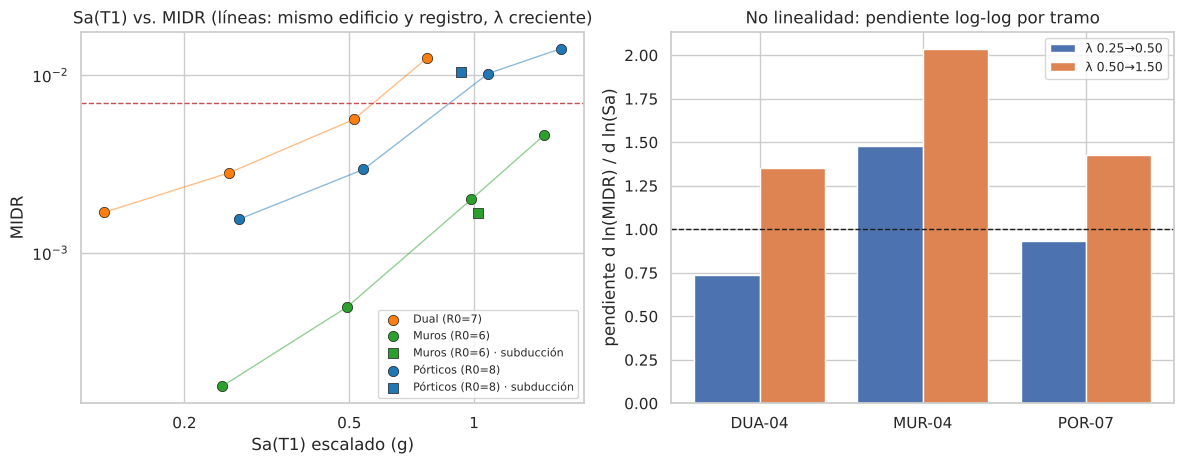

,arquetipo,sistema,b_elastico,b_inelastico
0,DUA-04,dual,0.74,1.35
1,MUR-04,muros,1.48,2.03
2,POR-07,porticos,0.93,1.43


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
for s, g in df.groupby("sistema"):
    for _, gg in g.groupby(["id_arquetipo", "id_registro"]):
        gg = gg.sort_values("Sa_T1_g")
        ax[0].plot(gg.Sa_T1_g, gg.MIDR, "-", color=COLORES[s], alpha=0.5, lw=1)
    mk = np.where(g.dominio == "Peru_subduccion", "s", "o")
    for m in ("o", "s"):
        gm = g[mk == m]
        ax[0].scatter(gm.Sa_T1_g, gm.MIDR, c=COLORES[s], marker=m, s=55, edgecolor="k", lw=0.5,
                      label=f"{ETIQ[s]}{' · subducción' if m == 's' else ''}" if len(gm) else None)
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].xaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5)))
ax[0].xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
ax[0].xaxis.set_minor_formatter(NullFormatter())
ax[0].set(xlabel="Sa(T1) escalado (g)", ylabel="MIDR",
          title="Sa(T1) vs. MIDR (líneas: mismo edificio y registro, λ creciente)")
ax[0].axhline(LIM_0007, color="r", ls="--", lw=1)
ax[0].legend(fontsize=8)

# Pendiente log-log por arquetipo (rango elástico: λ ≤ 0.5; inelástico: λ ≥ 1.0)
filas = []
for (a, reg), g in df[df.dominio == "NGA-West2"].groupby(["id_arquetipo", "id_registro"]):
    g = g.set_index("nivel_escala")
    if {0.25, 0.5, 1.0, 1.5} <= set(g.index):
        b_el = np.log(g.MIDR[0.5] / g.MIDR[0.25]) / np.log(2)
        b_in = np.log(g.MIDR[1.5] / g.MIDR[0.5]) / np.log(3)
        filas.append(dict(arquetipo=a, sistema=g.sistema.iloc[0], b_elastico=b_el, b_inelastico=b_in))
pend = pd.DataFrame(filas)
if len(pend):
    x = np.arange(len(pend))
    ax[1].bar(x - 0.2, pend.b_elastico, 0.4, label="λ 0.25→0.50")
    ax[1].bar(x + 0.2, pend.b_inelastico, 0.4, label="λ 0.50→1.50")
    ax[1].axhline(1, color="k", ls="--", lw=1)
    ax[1].set(xticks=x, xticklabels=pend.arquetipo, ylabel="pendiente d ln(MIDR) / d ln(Sa)",
              title="No linealidad: pendiente log-log por tramo")
    ax[1].legend(fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "eda_SaT1_vs_MIDR.png", dpi=150); plt.show()
pend.round(2)

## 5. Correlación de Spearman: 31 features vs. targets
Spearman (por rangos) capta relaciones monótonas no lineales, como intensidad–deriva, sin suponer linealidad. `sistema` se codifica como ordinal (pórticos 0, dual 1, muros 2) **solo para este gráfico**. Las variables constantes en la muestra (por ejemplo, Z = 0.45 en todo el dataset) se excluyen y se listan.

Variables constantes excluidas (2): ['Z', 'U']


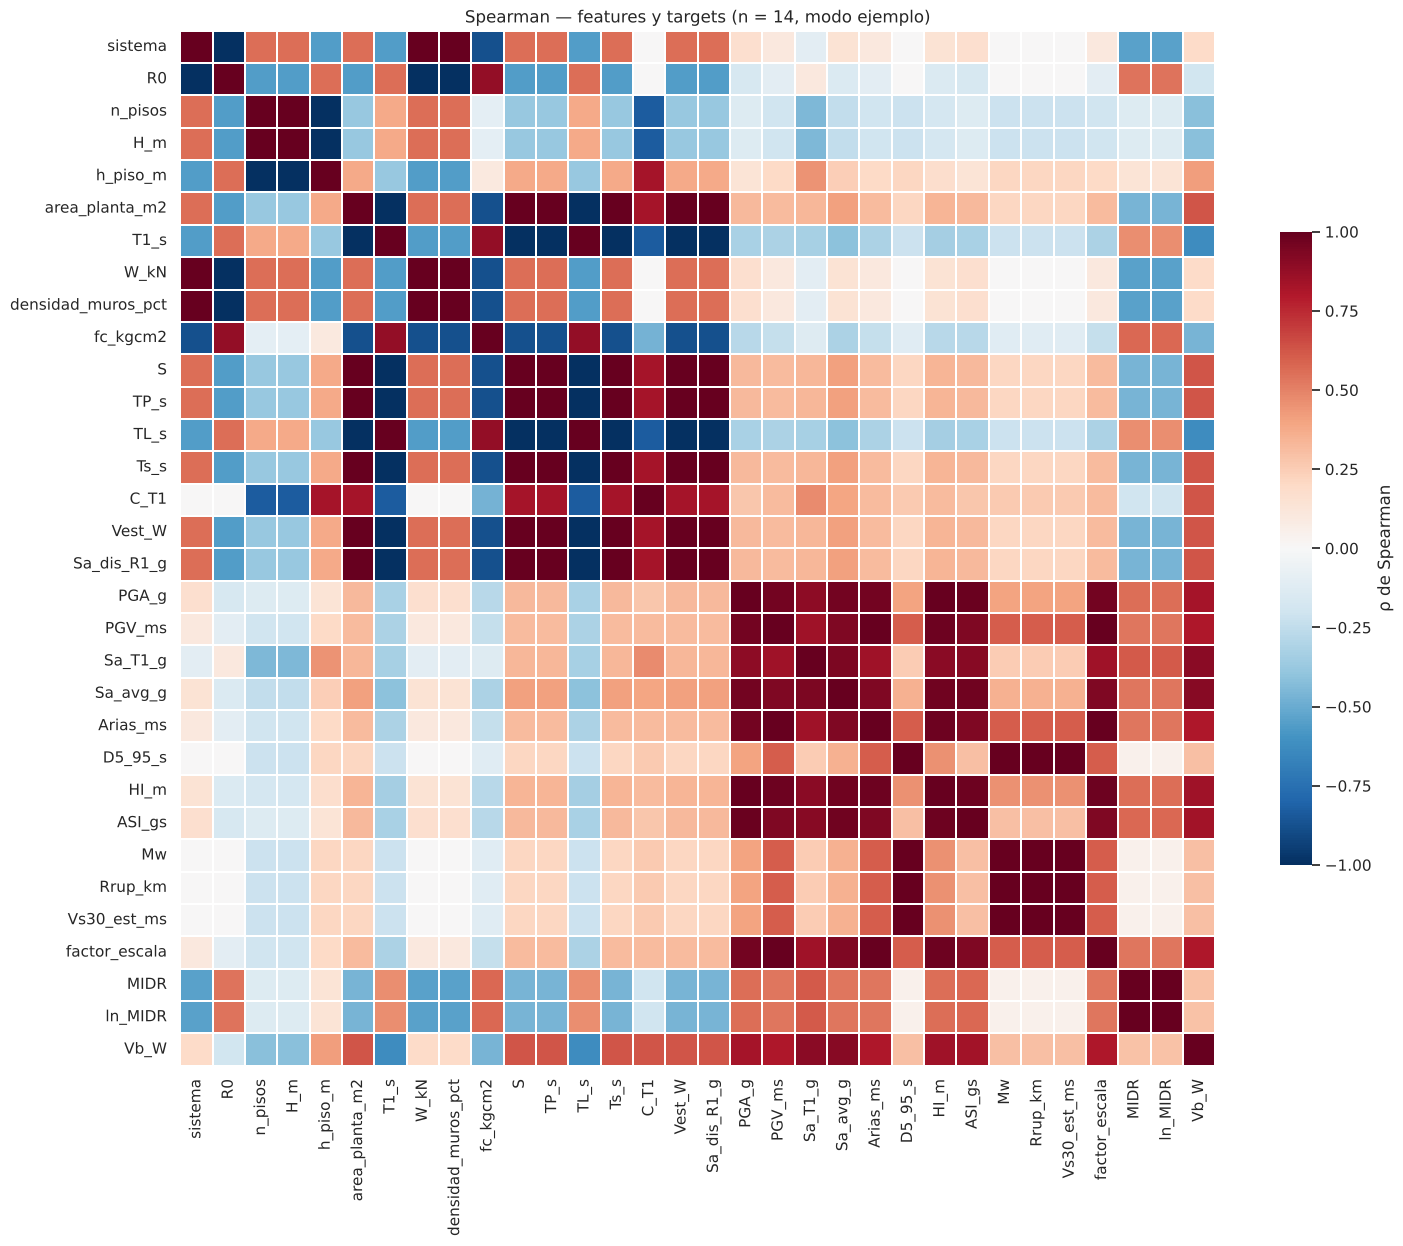

,ln_MIDR,Vb_W
Sa_T1_g,0.61,0.90
ASI_gs,0.58,0.84
fc_kgcm2,0.57,-0.46
PGA_g,0.56,0.83
HI_m,0.56,0.85
R0,0.55,-0.19
W_kN,-0.55,0.19
densidad_muros_pct,-0.55,0.19
sistema,-0.55,0.19
Arias_ms,0.54,0.81


In [10]:
X = df[FEATURES_X + TARGETS].copy()
X["sistema"] = X.sistema.map({"porticos": 0, "dual": 1, "muros": 2})
constantes = [c for c in X.columns if X[c].nunique() <= 1]
Xv = X.drop(columns=constantes)
rho = Xv.corr(method="spearman")
print(f"Variables constantes excluidas ({len(constantes)}): {constantes}")
fig, ax = plt.subplots(figsize=(15, 12.5))
sns.heatmap(rho, cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True, linewidths=0.3,
            cbar_kws={"shrink": 0.6, "label": "ρ de Spearman"}, ax=ax)
ax.set_title(f"Spearman — features y targets (n = {len(df)}, modo {MODO})")
plt.tight_layout(); plt.savefig(FIG / "eda_spearman_dataset.png", dpi=150); plt.show()
top = rho[["ln_MIDR", "Vb_W"]].drop(index=TARGETS, errors="ignore")
top.reindex(top.ln_MIDR.abs().sort_values(ascending=False).index).head(12).round(2)

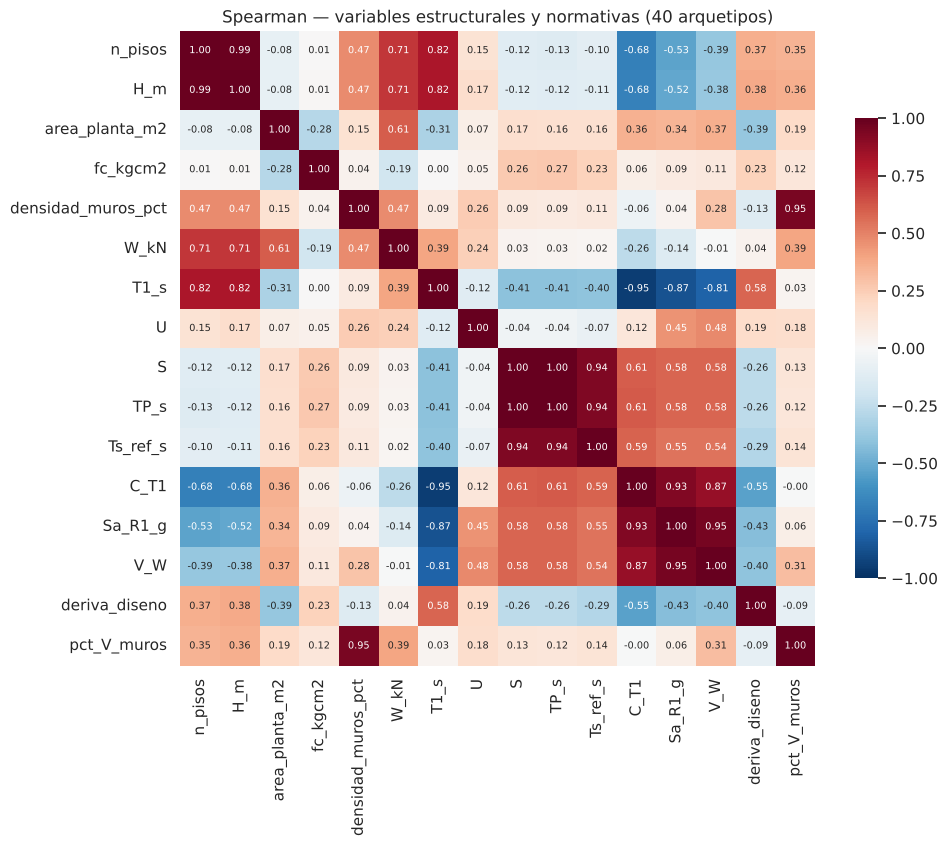

Redundancias |ρ| ≥ 0.9 (candidatas a eliminar o a interpretar juntas):
   ('n_pisos', 'H_m', np.float64(0.99))
   ('densidad_muros_pct', 'pct_V_muros', np.float64(0.95))
   ('T1_s', 'C_T1', np.float64(-0.95))
   ('S', 'TP_s', np.float64(1.0))
   ('S', 'Ts_ref_s', np.float64(0.94))
   ('TP_s', 'Ts_ref_s', np.float64(0.94))
   ('C_T1', 'Sa_R1_g', np.float64(0.93))
   ('Sa_R1_g', 'V_W', np.float64(0.95))


In [11]:
# Correlación a nivel de catálogo (40 arquetipos: datos reales, n suficiente)
cc = cat[["n_pisos", "H_m", "area_planta_m2", "fc_kgcm2", "densidad_muros_pct", "W_kN", "T1_s",
          "U", "S", "TP_s", "Ts_ref_s", "C_T1", "Sa_R1_g", "V_W", "deriva_diseno", "pct_V_muros"]]
rc = cc.corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8.5))
sns.heatmap(rc, cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, square=True, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Spearman — variables estructurales y normativas (40 arquetipos)")
plt.tight_layout(); plt.savefig(FIG / "eda_spearman_catalogo.png", dpi=150); plt.show()
print("Redundancias |ρ| ≥ 0.9 (candidatas a eliminar o a interpretar juntas):")
pares = [(a, b, round(rc.loc[a, b], 2)) for i, a in enumerate(rc) for b in rc.columns[i + 1:]
         if abs(rc.loc[a, b]) >= 0.9]
for p in pares:
    print("  ", p)

## 6. Sobrerresistencia Ω
$\Omega = (V_b/W)_{NLTHA} / (V/W)_{E.030}$. Cuando la estructura fluye, $V_b$ deja de crecer con la intensidad (saturación) y Ω estima la sobrerresistencia real frente al cortante de diseño.

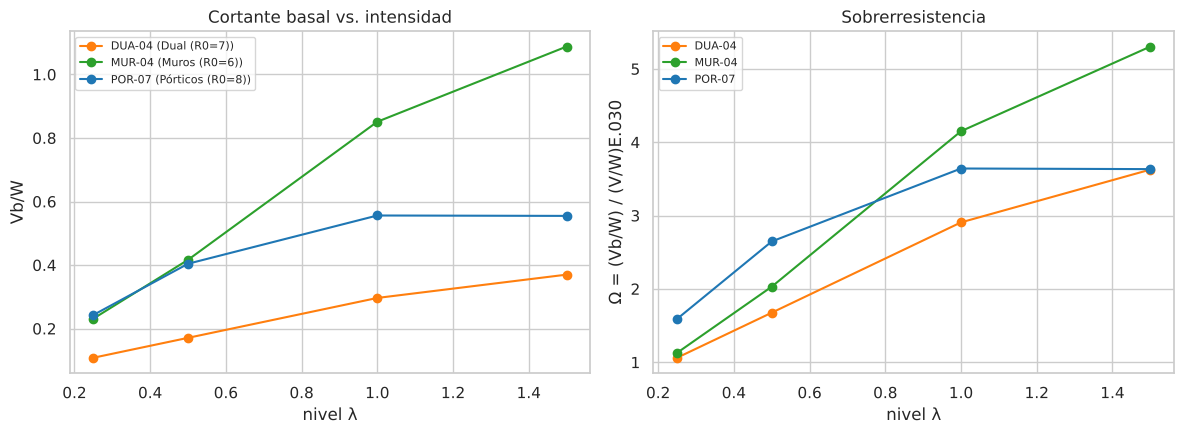

nivel_escala,0.25,0.5,1.0,1.5,saturacion_Vb_1.0→1.5_%
id_arquetipo,,,,,
DUA-04,1.06,1.68,2.91,3.63,24.7
MUR-04,1.13,2.03,4.15,5.30,27.8
POR-07,1.59,2.65,3.64,3.63,-0.2


In [12]:
df["Omega"] = df.Vb_W / df.Vest_W
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, g in df[df.dominio == "NGA-West2"].groupby("id_arquetipo"):
    g = g.sort_values("nivel_escala"); s = g.sistema.iloc[0]
    ax[0].plot(g.nivel_escala, g.Vb_W, "o-", color=COLORES[s], label=f"{a} ({ETIQ[s]})")
    ax[1].plot(g.nivel_escala, g.Omega, "o-", color=COLORES[s], label=a)
ax[0].set(xlabel="nivel λ", ylabel="Vb/W", title="Cortante basal vs. intensidad")
ax[1].set(xlabel="nivel λ", ylabel="Ω = (Vb/W) / (V/W)E.030", title="Sobrerresistencia")
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "eda_sobrerresistencia.png", dpi=150); plt.show()
tab = df[df.dominio == "NGA-West2"].pivot_table(index="id_arquetipo", columns="nivel_escala",
                                                values="Omega").round(2)
tab["saturacion_Vb_1.0→1.5_%"] = (100 * (df[df.nivel_escala == 1.5].set_index("id_arquetipo").Vb_W /
                                   df[(df.nivel_escala == 1.0) & (df.dominio == "NGA-West2")]
                                   .set_index("id_arquetipo").Vb_W - 1)).round(1)
tab

## 7. Hallazgos automáticos

In [13]:
print(f"MODO: {MODO}  (n = {len(df)})")
print(f"1. T1 modal / E.030 (mediana): pórticos {ratio_T.loc['porticos','median']}, dual {ratio_T.loc['dual','median']}, "
      f"muros {ratio_T.loc['muros','median']}: la fórmula hn/CT subestima el periodo de los duales.")
print(f"2. Cortante en muros: dual {cat.loc[cat.sistema=='dual','pct_V_muros'].min():.0f}–"
      f"{cat.loc[cat.sistema=='dual','pct_V_muros'].max():.0f} %, muros ≥ "
      f"{cat.loc[cat.sistema=='muros','pct_V_muros'].min():.0f} %.")
if len(pend):
    print(f"3. Pendiente ln MIDR–ln Sa: tramo elástico {pend.b_elastico.median():.2f}, "
          f"tramo inelástico {pend.b_inelastico.median():.2f} (mediana): la relación no es lineal.")
om = df[(df.sistema == 'porticos') & (df.nivel_escala >= 1.0) & (df.dominio == 'NGA-West2')].Omega
if len(om):
    print(f"4. Ω en pórticos fluyendo (λ ≥ 1.0): {om.min():.2f}–{om.max():.2f}")
print(f"5. Variables constantes en la muestra: {constantes}")
if MODO == "ejemplo":
    print("\nRECORDATORIO: los puntos 3 y 4 vienen de 14 filas ilustrativas; repetir con el dataset real.")

MODO: ejemplo  (n = 14)
1. T1 modal / E.030 (mediana): pórticos 1.19, dual 1.44, muros 1.15: la fórmula hn/CT subestima el periodo de los duales.
2. Cortante en muros: dual 31–61 %, muros ≥ 86 %.
3. Pendiente ln MIDR–ln Sa: tramo elástico 0.93, tramo inelástico 1.43 (mediana): la relación no es lineal.
4. Ω en pórticos fluyendo (λ ≥ 1.0): 3.63–3.64
5. Variables constantes en la muestra: ['Z', 'U']

RECORDATORIO: los puntos 3 y 4 vienen de 14 filas ilustrativas; repetir con el dataset real.
